# 02 — Split & Baseline

Goal: fix the train/test split and set the bar every model must beat.

Rules
- The test set is not touched until the final evaluation (step 7).
- Baselines are scored with 5-fold CV on the train set only.
- Cleaning and splitting live in `src/data.py` (reused by later notebooks and the API).

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, average_precision_score, f1_score,make_scorer, precision_score, recall_score,roc_auc_score)
from sklearn.model_selection import StratifiedKFold, cross_validate
sys.path.append(str(Path('..').resolve()))
from src.data import RANDOM_STATE, get_split

np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 50)

REPORT_DIR = Path('../reports')
FIG_DIR = REPORT_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f'{name}.png', dpi=150, bbox_inches='tight')

## 1. Split

In [2]:
X_train, X_test, y_train, y_test = get_split()
summary = pd.DataFrame({
    'rows': [len(X_train), len(X_test)],
    'churn_rate_%': [y_train.mean() * 100, y_test.mean() * 100],
}, index=['train', 'test']).round(2)
display(summary)
print('features:', X_train.shape[1])

,rows,churn_rate_%
train,5634,26.54
test,1409,26.54


features: 19


**Result:** 5,634 train / 1,409 test rows, both with a 26.5% churn rate (stratified split, seed 42). `X_test` and `y_test` are not used again until the final evaluation.

## 2. Baselines (5-fold CV on train)

- `Dummy: most_frequent`: always predicts No.
- `Dummy: stratified`: random guesses using the train class rates.
- `Rule: month-to-month`: predicts churn for month-to-month contracts. Fixed rule from the EDA, nothing is fitted. The EDA looked at all rows, so treat it as a rough bar.

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scorers = {
    'accuracy': 'accuracy',
    'precision': make_scorer(precision_score, zero_division=0),
    'recall': 'recall',
    'f1': make_scorer(f1_score, zero_division=0),
    'roc_auc': 'roc_auc',
    'pr_auc': 'average_precision',
}

models = {
    'Dummy: most_frequent': DummyClassifier(strategy='most_frequent'),
    'Dummy: stratified': DummyClassifier(strategy='stratified',
                                         random_state=RANDOM_STATE),
}

rows = {}
for name, model in models.items():
    res = cross_validate(model, X_train, y_train, cv=cv, scoring=scorers)
    rows[name] = {m: (res[f'test_{m}'].mean(), res[f'test_{m}'].std())
                  for m in scorers}

y_rule = (X_train['Contract'] == 'Month-to-month').astype(int)
rule_scores = {
    'accuracy': accuracy_score(y_train, y_rule),
    'precision': precision_score(y_train, y_rule, zero_division=0),
    'recall': recall_score(y_train, y_rule),
    'f1': f1_score(y_train, y_rule),
    'roc_auc': roc_auc_score(y_train, y_rule),
    'pr_auc': average_precision_score(y_train, y_rule),
}
rows['Rule: month-to-month'] = {m: (v, np.nan) for m, v in rule_scores.items()}

records = []
for name, d in rows.items():
    rec = {'model': name}
    for m, (mean, std) in d.items():
        rec[f'{m}_mean'] = mean
        rec[f'{m}_std'] = std
    records.append(rec)
results = pd.DataFrame(records).set_index('model')
results.round(4).to_csv(REPORT_DIR / 'baseline_cv_results.csv')

def fmt(mean, std):
    return f'{mean:.3f}' if np.isnan(std) else f'{mean:.3f} +/- {std:.3f}'

display(pd.DataFrame(
    {m: [fmt(results.loc[n, f'{m}_mean'], results.loc[n, f'{m}_std'])
         for n in results.index] for m in scorers},
    index=results.index))

,accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,
Dummy: most_frequent,0.735 +/- 0.000,0.000 +/- 0.000,0.000 +/- 0.000,0.000 +/- 0.000,0.500 +/- 0.000,0.265 +/- 0.000
Dummy: stratified,0.614 +/- 0.013,0.275 +/- 0.025,0.278 +/- 0.025,0.276 +/- 0.025,0.507 +/- 0.017,0.269 +/- 0.007
Rule: month-to-month,0.655,0.427,0.887,0.577,0.729,0.409


**Result:** `most_frequent` gets 73.5% accuracy but recall and F1 of 0. A no-skill model has PR-AUC equal to the churn rate (~0.27). The month-to-month rule reaches F1 0.58 with recall 0.89 and precision 0.43.

**Bar to beat:** F1 ~0.58, PR-AUC > 0.41, ROC-AUC > 0.73. Accuracy is not used to rank models.

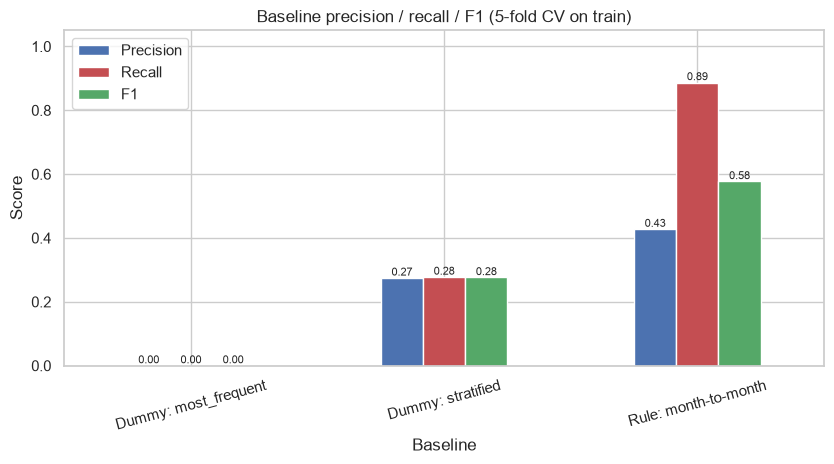

In [4]:
plot_df = results[['precision_mean', 'recall_mean', 'f1_mean']].copy()
plot_df.columns = ['Precision', 'Recall', 'F1']

ax = plot_df.plot(kind='bar', figsize=(8.5, 4.8), rot=15,
                  color=['#4C72B0', '#C44E52', '#55A868'])
for c in ax.containers:
    ax.bar_label(c, fmt='%.2f', fontsize=8)
ax.set_title('Baseline precision / recall / F1 (5-fold CV on train)')
ax.set_xlabel('Baseline')
ax.set_ylabel('Score')
ax.set_ylim(0, 1.05)
save_fig('10_baseline_scores')
plt.show()

**Result:** only the month-to-month rule has useful recall; the dummy models score zero or at random level.